# setup + imports

In [1]:
%pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage import filters, measure
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

In [3]:
print(os.listdir('train_data'))
print(len(os.listdir('test_data')), sorted(os.listdir('test_data'))[:5])

['all_piano_notes_duration.png', 'empty_piano_score.png', '.ipynb_checkpoints']
2001 ['.ipynb_checkpoints', '0.png', '1.png', '10.png', '100.png']


In [4]:
ids = []
paths = []
for f in os.listdir('test_data'):
  if f.endswith('.png'):
    ids.append(int(f[:-4]))                   
    paths.append(os.path.join('test_data', f))
test_data = pd.DataFrame({'id': ids, 'path': paths}).sort_values('id').reset_index(drop=True)
print(len(test_data))
print(test_data.head())

2000
   id             path
0   0  test_data/0.png
1   1  test_data/1.png
2   2  test_data/2.png
3   3  test_data/3.png
4   4  test_data/4.png


# preprocessing

In [12]:
def load_mask(path):
  gray = np.array(Image.open(path).convert('L'))  
  return gray < 128 

def find_lines(mask):
    line_rows = np.where(mask.mean(axis=1) > 0.5)[0]   
    lines = []
    for r in line_rows:                                
        if len(lines) > 0 and r - lines[-1][-1] <= 1:
            lines[-1].append(r)
        else:
          lines.append([r])
    line_y = [np.mean(l) for l in lines]   
    spacing = np.mean(np.diff(line_y)) 
    return lines, line_y, spacing

def remove_lines(mask, lines):
    out = mask.copy()
    for rows in lines:
        above = mask[rows[0] - 1, :]
        below = mask[rows[-1] + 1, :]
        for x in range(mask.shape[1]):
            if not above[x] and not below[x]:
                for r in rows:
                    out[r, x] = False
    return out


In [13]:
def split_notes(clean):
    has_ink = clean.any(axis=0)                      
    pieces = []
    start = None
    for x in range(len(has_ink)):
        if has_ink[x] and start is None:                 
            start = x
        if not has_ink[x] and start is not None:         
            pieces.append((start, x))
            start = None
    if start is not None:
        pieces.append((start, len(has_ink)))

    merged = []
    for a, b in pieces:
        if len(merged) > 0 and a - merged[-1][1] <= 3:   
            merged[-1][1] = b
        else:
            merged.append([a, b])
    return merged[1:] 

In [14]:
def read_note(piece, line_y, spacing):
    rows = np.where(piece.any(axis=1))[0]                  
    head_y = rows.max() - spacing / 2                         
 
    steps = round((line_y[-1] - head_y) / (spacing / 2))
    tone = 'CDEFGAB'[(6 + steps) % 7]

    r = int(round(head_y))
    cols = np.where(piece[r, :])[0]                   
    head_x = (cols.min() + cols.max()) // 2
    hollow = not piece[r, head_x]  

    col_counts = piece.sum(axis=0)
    has_stem = col_counts.max() > 2 * spacing
    stem_x = col_counts.argmax() 

    if hollow:
        duration = '1/2' if has_stem else '1/1'
    elif not has_stem or stem_x + 2 >= piece.shape[1]: 
        duration = '1/4'
    else:
        col = piece[:int(head_y - spacing / 2), stem_x + 2]
        flags = 0
        for i in range(len(col)):
            if col[i] and (i == 0 or not col[i - 1]):
                flags += 1
        duration = ['1/4', '1/8', '1/16'][min(flags, 2)]
    return tone, duration

# model (kinda lmao)

In [15]:
mask = load_mask('example.png')
lines, line_y, spacing = find_lines(mask)
clean = remove_lines(mask, lines)
for a, b in split_notes(clean):
  print(read_note(clean[:, a:b], line_y, spacing))

('A', '1/1')
('B', '1/2')
('C', '1/4')
('D', '1/8')
('E', '1/16')
('F', '1/4')
('G', '1/4')


In [16]:
dur_value = {'1/1': 1, '1/2': 0.5, '1/4': 0.25, '1/8': 0.125, '1/16': 0.0625}
ans1 = []
ans2 = []
ans3 = []
for p in test_data['path']:
    mask = load_mask(p)
    lines, line_y, spacing = find_lines(mask)
    clean = remove_lines(mask, lines)
    total = 0
    parts = []
    for a, b in split_notes(clean):
        tone, d = read_note(clean[:, a:b], line_y, spacing)
        total += dur_value[d]
        parts.append(tone + '-' + d)
    ans1.append(len(parts))
    ans2.append(total)
    ans3.append(' '.join(parts))

3       1
4       3
6       1
7       1
8       2
       ..
96     20
97     18
98     23
99     15
100    16
Name: count, Length: 97, dtype: int64
10 45


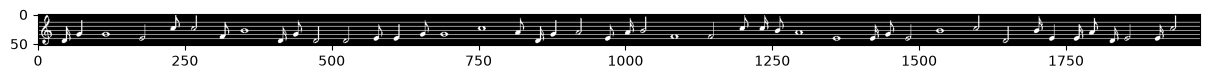

In [17]:
print(pd.Series(ans1).value_counts().sort_index())  

for i in range(len(ans1)):
    if ans1[i] > 10 or ans1[i] == 0:                  
        print(i, ans1[i])
        plt.figure(figsize=(15, 3)); plt.imshow(load_mask(test_data['path'].iloc[i]), cmap='gray'); plt.show()
        break

# submisie

In [11]:
subtask1 = pd.DataFrame({
    'subtaskID': 1,
    'datapointID': test_data['id'],
    'answer': ans1
})

subtask2 = pd.DataFrame({
    'subtaskID': 2,
    'datapointID': test_data['id'],
    'answer': ans2
})

subtask3 = pd.DataFrame({
    'subtaskID': 3,
    'datapointID': test_data['id'],
    'answer': ans3
})

submission = pd.concat([subtask1, subtask2, subtask3], ignore_index=True)
submission.to_csv('submission.csv', index=False)